# Presidential Coattails and Senate Performance: How Do Presidential Elections Shape U.S. Senate Outcomes? (1976 - 2020)

**Author:** Arshad Saleh


## 1. Project Questions

This project looks at how presidential election results have shaped national  U.S. Senate results from 1976 to 2020. The questions that are being addressed are:

1. **Does the incumbent party gain or lose Senate seats depending on whether it is a presidential year or a midterm year?** Senate elections take place every 2 years but the political environment changes significantly between presidential election years, when voter turnout is higher, and midterm election years, when voter the president's party usually performs poorly. This questions looks at whether this is consistent across 1976 to 2020.

2. **Does a stronger presidential vote share translate into more Senate seats won in the same election year (the coattail effect)?** This question asks whether the president winning by a large margin also leads to more Senate races won by the same party and whether this is consistent across multiple election cycles.

3. **How does net Senate seat change vary by party and election type over time?** This questions analyzes whether Democrats and Republicans experience systematically different Senate results by computing the net seats gained or lost by each party across every election year. This also looks at whether midterm years produce more volatile swings than presidential election years.



## 2. Data Description

### Datasets

Two datasets are used in this project and both are sourced from the MIT Election Data and Science Lab:

- **U.S. Senate Election Results (1976–2020):** `1976-2020-senate.csv`, one row per candidate per state per election year (3,629 rows before cleaning). Relevant columns: `year`, `state`, `candidate`, `party_simplified`, `candidatevotes`, `totalvotes`, `stage`, `special`.

- **U.S. Presidential Election Results (1976–2020):** `1976-2020-president.csv`, one row per candidate per state per election year (4,287 rows before cleaning). Relevant columns: `year`, `state`, `candidate`, `party_simplified`, `candidatevotes`, `totalvotes`, `writein`.

Both datasets share the columns `year`, `state`, and `party_simplified`, which serve as the common keys used to join them.

### Preprocessing

These cleaning steps were applied to the Senate dataset:
- Only general elections (`stage = 'gen'`) and exclude special elections (`special = False`) were kept.
- Only Democrat and Republican candidates (`party_simplified` in `['DEMOCRAT', 'REPUBLICAN']`) were kept.
- The 2021 special election year was excluded
- A derived column `election_type` ('presidential' or 'midterm') based on the cycle was added.

The following cleaning steps were applied to the presidential dataset:
- Only Democrat and Republican candidates were kept.
- Write-in candidates (`writein = False`) were removed.

There were no missing values in the key columns (`candidatevotes`, `totalvotes`) in either dataset after filtering.

### Database Schema

The cleaned data was loaded into a SQLite database (`elections.db`) with two tables:
```
senate_elections(
    year INTEGER,
    state TEXT,
    candidate TEXT,
    party_simplified TEXT,
    candidatevotes INTEGER,
    totalvotes INTEGER,
    special BOOLEAN,
    election_type TEXT
)

president_elections(
    year INTEGER,
    state TEXT,
    candidate TEXT,
    party_simplified TEXT,
    candidatevotes INTEGER,
    totalvotes INTEGER
)
```

Both tables are joined on `year` and `party_simplified` for the coattail analysis.

## 3. Analysis


In [3]:
import project
import pandas as pd

In [5]:
senate_df = project.load_senate_data('data/1976-2020-senate.csv')
president_df = project.load_president_data('data/1976-2020-president.csv')

print('Senate election election data rows after cleaning:', len(senate_df))
print('Presidential election data rows after cleaning:', len(president_df))

Senate election election data rows after cleaning: 1538
Presidential election data rows after cleaning: 1222


/Users/arshad/Documents/election-analysis/project.py:111: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df['election_type'][df['year'].isin(pres_years)] = 'presidential'
/Users/arshad/Documents/election-analysis/project.py:111: SettingWithCo

In [6]:
senate_df.head()

,year,state,candidate,party_simplified,candidatevotes,totalvotes,special,election_type
0,1976,ARIZONA,SAM STEIGER,REPUBLICAN,321236,741210,False,presidential
2,1976,ARIZONA,DENNIS DECONCINI,DEMOCRAT,400334,741210,False,presidential
6,1976,CALIFORNIA,S. I. (SAM) HAYAKAWA,REPUBLICAN,3748973,7470586,False,presidential
7,1976,CALIFORNIA,JOHN V. TUNNEY,DEMOCRAT,3502862,7470586,False,presidential
10,1976,CONNECTICUT,"LOWELL P. WEICKER, JR.",REPUBLICAN,785683,1361666,False,presidential


In [7]:
president_df.head()

,year,state,candidate,party_simplified,candidatevotes,totalvotes
0,1976,ALABAMA,"CARTER, JIMMY",DEMOCRAT,659170,1182850
1,1976,ALABAMA,"FORD, GERALD",REPUBLICAN,504070,1182850
7,1976,ALASKA,"FORD, GERALD",REPUBLICAN,71555,123574
8,1976,ALASKA,"CARTER, JIMMY",DEMOCRAT,44058,123574
11,1976,ARIZONA,"FORD, GERALD",REPUBLICAN,418642,742719


In [8]:
# Create and populate the database with both tables
project.create_database('elections.db')
conn = project.connect('elections.db')

project.add_dataframe(conn, senate_df, 'senate_elections')
project.add_dataframe(conn, president_df, 'president_elections')

print('Database created and populated')

Database created and populated


### Question 1: Senate Seats Won by Party and Election Type

For Question 1, we query the Senate table to find the number of seats won by each party in each election cycle. The winner of each state race is identified as the candidate with the most votes and then seats are counted per party per year using GROUP BY and COUNT.

In [9]:
seats_df = project.query_senate_seats_won(conn)
seats_df

,year,party_simplified,seats_won,election_type
0,1976,DEMOCRAT,22,presidential
1,1976,REPUBLICAN,11,presidential
2,1978,DEMOCRAT,15,midterm
3,1978,REPUBLICAN,18,midterm
4,1980,DEMOCRAT,13,presidential
5,1980,REPUBLICAN,20,presidential
6,1982,DEMOCRAT,20,midterm
7,1982,REPUBLICAN,13,midterm
8,1984,DEMOCRAT,16,presidential
9,1984,REPUBLICAN,17,presidential


In [10]:
# Count average seats won by party and election type
avg_seats = (seats_df
             .groupby(['election_type', 'party_simplified'])['seats_won']
             .mean()
             .reset_index())
avg_seats

,election_type,party_simplified,seats_won
0,midterm,DEMOCRAT,16.363636
1,midterm,REPUBLICAN,16.727273
2,presidential,DEMOCRAT,16.916667
3,presidential,REPUBLICAN,16.250000


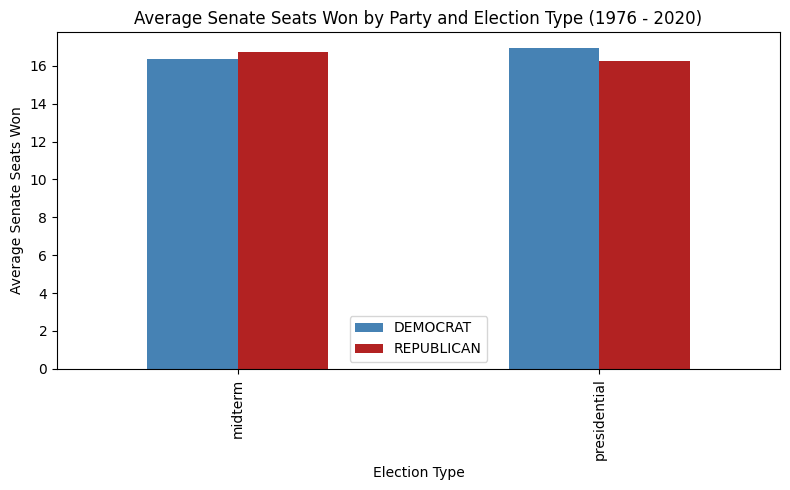

In [11]:
# Plot 1: Average seats won by party and election type
project.plot_seats_won_by_election_type(seats_df)

### Question 2: The Coattail Effect

For Question 2, we join the presidential and Senate tables on year and party_simplified, only looking at presidential election years. The query computes national presidential vote share using SUM(candidatevotes) / SUM(totalvotes) and Senate seats won using COUNT and MAX. This is all done using JOIN with GROUP BY.

In [12]:
coattail_df = project.query_coattail_effect(conn)
coattail_df

,year,party_simplified,pres_vote_share,senate_seats_won
0,1976,DEMOCRAT,49.85,22
1,1976,REPUBLICAN,47.64,11
2,1980,DEMOCRAT,41.02,13
3,1980,REPUBLICAN,50.46,20
4,1984,DEMOCRAT,40.42,16
5,1984,REPUBLICAN,58.46,17
6,1988,DEMOCRAT,45.55,19
7,1988,REPUBLICAN,53.11,14
8,1992,DEMOCRAT,42.88,20
9,1992,REPUBLICAN,37.09,14


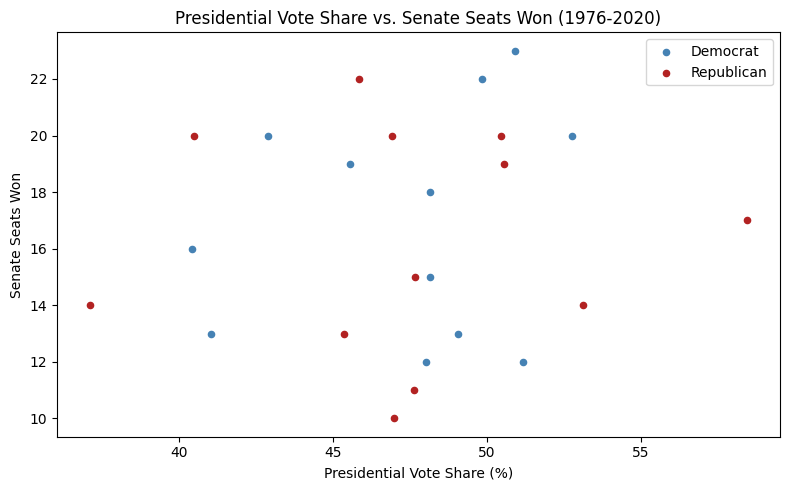

In [13]:
# Plot 2: Scatter plot of Presidential vote share compared to Senate seats won
project.plot_coattail_effect(coattail_df)

### Question 3: Net Senate Seat Change Over Time

For Question 3, we use a parameterized query that accepts a party name as input and returns the seats won per year for that party. The net change is then computed. We run the query separately for each party and combine the results.

In [14]:
dem_df = project.query_net_seat_change_by_party(conn, 'DEMOCRAT')
dem_df

,year,party_simplified,seats_won,election_type,net_seat_change
0,1976,DEMOCRAT,22,presidential,NaN
1,1978,DEMOCRAT,15,midterm,-7.0
2,1980,DEMOCRAT,13,presidential,-2.0
3,1982,DEMOCRAT,20,midterm,7.0
4,1984,DEMOCRAT,16,presidential,-4.0
5,1986,DEMOCRAT,19,midterm,3.0
6,1988,DEMOCRAT,19,presidential,0.0
7,1990,DEMOCRAT,17,midterm,-2.0
8,1992,DEMOCRAT,20,presidential,3.0
9,1994,DEMOCRAT,14,midterm,-6.0


In [15]:
rep_df = project.query_net_seat_change_by_party(conn, 'REPUBLICAN')
rep_df

,year,party_simplified,seats_won,election_type,net_seat_change
0,1976,REPUBLICAN,11,presidential,NaN
1,1978,REPUBLICAN,18,midterm,7.0
2,1980,REPUBLICAN,20,presidential,2.0
3,1982,REPUBLICAN,13,midterm,-7.0
4,1984,REPUBLICAN,17,presidential,4.0
5,1986,REPUBLICAN,14,midterm,-3.0
6,1988,REPUBLICAN,14,presidential,0.0
7,1990,REPUBLICAN,16,midterm,2.0
8,1992,REPUBLICAN,14,presidential,-2.0
9,1994,REPUBLICAN,19,midterm,5.0


In [16]:
net_df = project.compute_net_seat_change(seats_df)
net_df

,year,party_simplified,seats_won,election_type,net_seat_change
0,1976,DEMOCRAT,22,presidential,NaN
2,1978,DEMOCRAT,15,midterm,-7.0
4,1980,DEMOCRAT,13,presidential,-2.0
6,1982,DEMOCRAT,20,midterm,7.0
8,1984,DEMOCRAT,16,presidential,-4.0
10,1986,DEMOCRAT,19,midterm,3.0
12,1988,DEMOCRAT,19,presidential,0.0
14,1990,DEMOCRAT,17,midterm,-2.0
16,1992,DEMOCRAT,20,presidential,3.0
18,1994,DEMOCRAT,14,midterm,-6.0


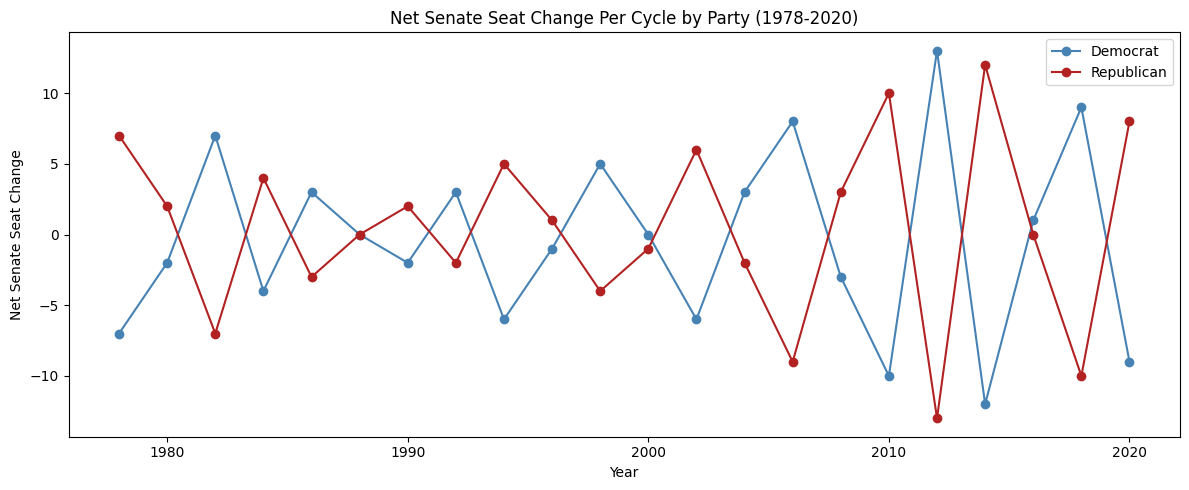

In [17]:
# Plot 3: Net Senate seat change per year by party
project.plot_net_seat_change_per_cycle(net_df)

### Summary Table

In [18]:
# Summary table: One row per election year showing both parties side by side
dem_seats = seats_df[seats_df['party_simplified'] == 'DEMOCRAT'][['year', 'election_type', 'seats_won']]
rep_seats = seats_df[seats_df['party_simplified'] == 'REPUBLICAN'][['year', 'seats_won']]

summary = pd.merge(dem_seats, rep_seats, on='year', how='inner')
summary = summary.rename(columns={'seats_won_x': 'dem_seats_won',
                                   'seats_won_y': 'rep_seats_won'})

summary

,year,election_type,dem_seats_won,rep_seats_won
0,1976,presidential,22,11
1,1978,midterm,15,18
2,1980,presidential,13,20
3,1982,midterm,20,13
4,1984,presidential,16,17
5,1986,midterm,19,14
6,1988,presidential,19,14
7,1990,midterm,17,16
8,1992,presidential,20,14
9,1994,midterm,14,19


In [ ]:
conn.close()

## 4. Results and Interpretation

**Question 1. Presidential vs. Midterm Years:**
The data shows that on average, Democrats win slightly more Senate seats in presidential years than in midterm years, while Republicans win slightly more in midterm years than in presidential years. This is very consistent with the midterm penalty which is that the party holding the White House tends to lose seats in midterm elections. However, the effect is moderate in magnitude when averaged across all cycles. This is because some midterms produce large swings while others are more neutral.

**Question 2. The Coattail Effect:**
There is a general positive association between the presidential vote share of a party and the number of Senate seats it wins in the same year. Parties that win the presidency by alot tend to also win more Senate seats. However, this relationship is not perfectly consistent partly because only about one-third of Senate seats are contested in any given presidential year. This means the seats available depend on which class of senators happens to be up for election and actually the overall party strength.

**Question 3. Net Seat Change Over Time:**
We observed that midterm years consistently produce bigger seat swings than presidential years, reflecting how midterms often serve as a feedback on the current president. The most dramatic swing in the dataset is Democrats losing 10 seats in 2010 and gaining 13 in 2012 and Republicans. The net changes between the two parties mirror each other closely across all cycles.

## 5. Conclusions

**Question 1:** The incumbent party does tend to lose Senate seats in midterm years and hold or gain seats in presidential years, though the effect is not much when averaged across all cycles. The pattern is more evident in years with large political waves, for example 2010 and 2014, than in calmer cycles.

**Question 2:** Higher presidential vote share is positively associated with winning more Senate seats in the same election year which is consistent with a coattail effect. The relationship is however, not strongly consistent across all cycles and results should be treated as associations rather than conclusions as there are only 12 presidential-year data points.

**Question 3:** Net Senate seat change is more volatile in midterm years than in presidential years. The two parties have nearly inversely proportional gains/losses across the full 1976–2020 period as a gain for one party typically means a loss for the other party.

**Limitations:**
- Only about 1/3 of Senate seats are contested each cycle due to the staggered three-class system, meaning the seats available in any given cycle reflect which candidates are running and not the full balance of power. This makes cycle-to-cycle comparisons less clear.
- The coattail scatter plot has only 12 data points per party, so patterns should be interpreted with caution.
- This analysis looks at national level trends only and does not account for state-level factors such as incumbency advantage or regional political shifts.